# Exploratory Data Analysis (EDA) — Telco Customer Churn
**Project:** Customer Churn Prediction & Retention Intelligence Platform (DEPI — Group 2)  
**Dataset:** IBM Telco Customer Churn (`Telco_Customer_Churn_Cleaned.csv`)  

This notebook unifies all 6 EDA stages into one structured workflow:
1. **Step 1 — Data Understanding:** Shape, schema, data types, and summary statistics
2. **Step 2 — Data Quality Assessment:** Missing values, duplicates, `TotalCharges` whitespace fix, and outliers
3. **Step 3 — Target Distribution Analysis:** Churn class imbalance
4. **Step 4 — Exploratory Data Analysis:** Categorical, service add-on, numerical, and correlation analysis
5. **Step 5 — Feature Engineering Preview & Insights:** Derived business features and key churn drivers
6. **Step 6 — Save Cleaned Dataset:** Export `cleaned_data.csv` for downstream modeling

## Step 1 — Load and Explore the Dataset

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", None)

DATA_PATH = "Telco_Customer_Churn_Cleaned.csv"
df = pd.read_csv(DATA_PATH)
print(f"Dataset shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Dataset shape: 7,043 rows x 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
print("=== Data Types & Non-Null Counts ===")
df.info()
print("\n=== Summary Statistics (Numerical) ===")
display(df.describe().T)
print("\n=== Summary Statistics (Categorical) ===")
display(df.describe(include="object").T)

=== Data Types & Non-Null Counts ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  Paper

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.00,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.734304,2266.794470,0.00,398.55,1394.55,3786.60,8684.80



=== Summary Statistics (Categorical) ===


,count,unique,top,freq
customerID,7043,7043,3186-AJIEK,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


## Step 2 — Data Quality Assessment & Cleaning

In [3]:
print("Missing values per column:")
print(df.isnull().sum())
print(f"\nDuplicate rows: {df.duplicated().sum()}")
print(f"Unique customerIDs: {df['customerID'].nunique()} / {len(df)}")

# Check whitespace or non-numeric entries in TotalCharges
total_num = pd.to_numeric(df["TotalCharges"], errors="coerce")
blank_mask = total_num.isna()
print(f"\nRows with blank/non-numeric TotalCharges: {blank_mask.sum()}")
if blank_mask.sum() > 0:
    display(df.loc[blank_mask, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

Missing values per column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate rows: 0
Unique customerIDs: 7043 / 7043

Rows with blank/non-numeric TotalCharges: 0


In [4]:
# Clean dataset: drop ID, fix TotalCharges (tenure == 0 -> 0.0), validate Churn
df_clean = df.copy()
df_clean.drop(columns=["customerID"], errors="ignore", inplace=True)
df_clean["TotalCharges"] = pd.to_numeric(df_clean["TotalCharges"], errors="coerce")
zero_tenure_nan = df_clean["TotalCharges"].isna() & (df_clean["tenure"] == 0)
df_clean.loc[zero_tenure_nan, "TotalCharges"] = 0.0
assert df_clean["TotalCharges"].isna().sum() == 0, "Unexpected NaNs remain in TotalCharges"

# Outlier check (IQR method) on numerical columns
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    outliers = ((df_clean[col] < q1 - 1.5 * iqr) | (df_clean[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col:15s} | min={df_clean[col].min():.2f}, max={df_clean[col].max():.2f}, IQR outliers={outliers}")

tenure          | min=0.00, max=72.00, IQR outliers=0
MonthlyCharges  | min=18.25, max=118.75, IQR outliers=0
TotalCharges    | min=0.00, max=8684.80, IQR outliers=0


### Data Quality Findings
- **No explicit nulls** in raw columns, except **11 rows** with whitespace `" "` in `TotalCharges` (all have `tenure == 0` — brand-new customers not billed yet), safely filled with `0.0`.
- **0 duplicate rows** and all `customerID` values are unique.
- **0 IQR outliers** in `tenure`, `MonthlyCharges`, or `TotalCharges`.

## Step 3 — Target Distribution Analysis (Churn Class Imbalance)

       Count  Percentage (%)
Churn                       
No      5174           73.46
Yes     1869           26.54


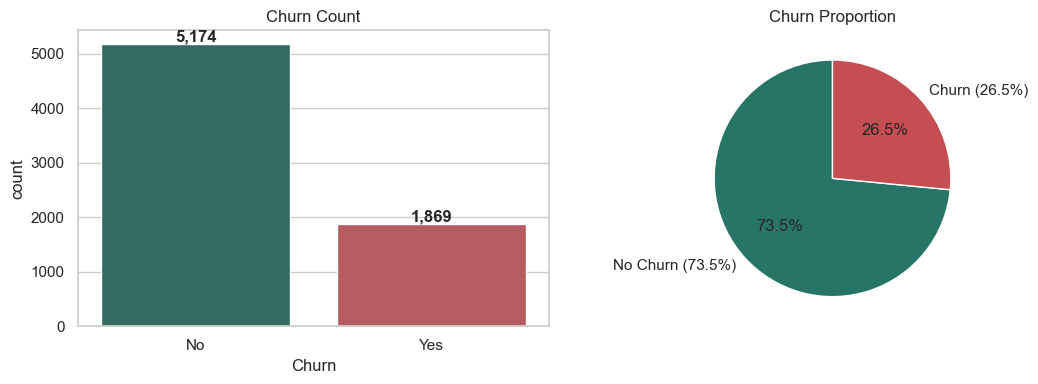

In [5]:
churn_counts = df_clean["Churn"].value_counts()
churn_pct = df_clean["Churn"].value_counts(normalize=True) * 100
print(pd.DataFrame({"Count": churn_counts, "Percentage (%)": churn_pct.round(2)}))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df_clean, x="Churn", ax=axes[0], palette=["#277567", "#c44e52"])
axes[0].set_title("Churn Count")
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom", fontweight="bold")

axes[1].pie(churn_counts, labels=["No Churn (73.5%)", "Churn (26.5%)"], autopct="%1.1f%%",
            colors=["#277567", "#c44e52"], startangle=90)
axes[1].set_title("Churn Proportion")
plt.tight_layout()
plt.show()

## Step 4 — Exploratory Data Analysis (Bivariate & Multivariate)

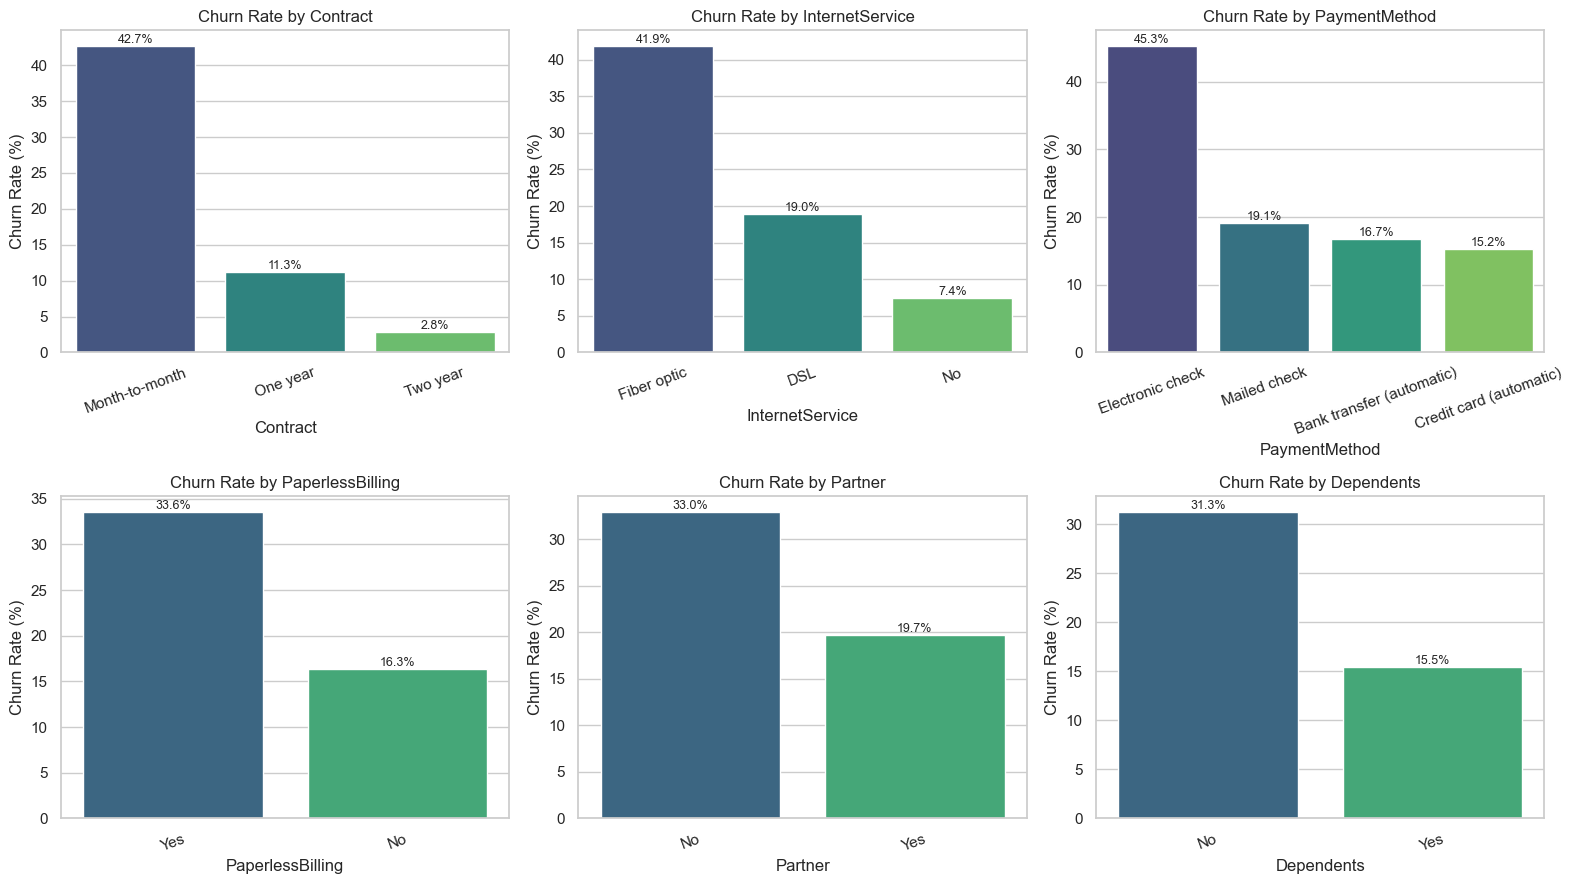

In [6]:
# Categorical features vs Churn rate
cat_cols = ["Contract", "InternetService", "PaymentMethod", "PaperlessBilling", "Partner", "Dependents"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, cat_cols):
    rate = (df_clean.assign(ChurnFlag=(df_clean["Churn"] == "Yes").astype(int))
            .groupby(col)["ChurnFlag"].mean().sort_values(ascending=False) * 100)
    sns.barplot(x=rate.index, y=rate.values, ax=ax, palette="viridis")
    ax.set_title(f"Churn Rate by {col}")
    ax.set_ylabel("Churn Rate (%)")
    ax.tick_params(axis="x", rotation=20)
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

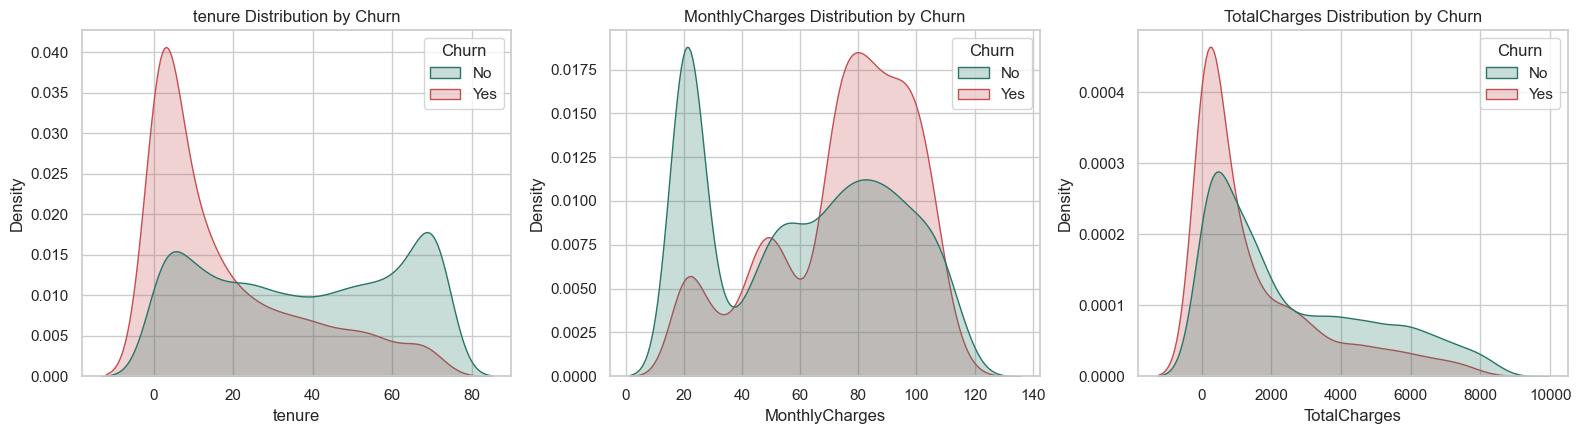

In [7]:
# Numerical features vs Churn
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.kdeplot(data=df_clean, x=col, hue="Churn", fill=True, common_norm=False,
                palette={"No": "#277567", "Yes": "#c44e52"}, ax=ax)
    ax.set_title(f"{col} Distribution by Churn")
plt.tight_layout()
plt.show()

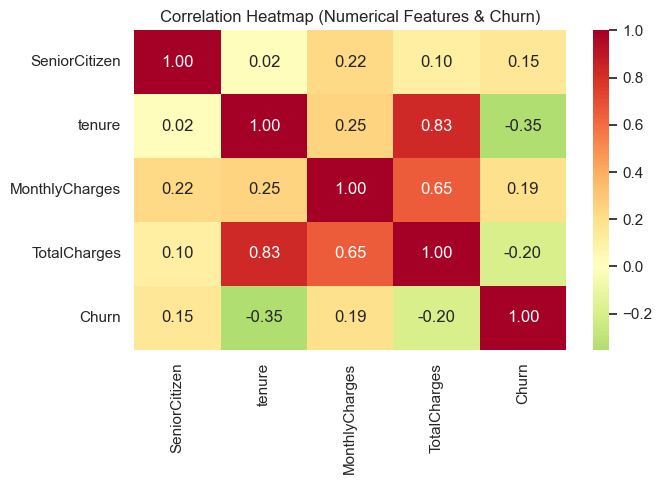

In [8]:
# Correlation heatmap for numerical features + target
num_df = df_clean[["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]].copy()
num_df["Churn"] = (df_clean["Churn"] == "Yes").astype(int)

plt.figure(figsize=(7, 5))
sns.heatmap(num_df.corr(), annot=True, fmt=".2f", cmap="RdYlGn_r", center=0)
plt.title("Correlation Heatmap (Numerical Features & Churn)")
plt.tight_layout()
plt.show()

## Step 5 — Key Insights & Findings
1. **Contract Type is the #1 Driver:** Month-to-month customers churn at **~42.7%**, compared to **~11.3%** for 1-year and **~2.8%** for 2-year contracts.
2. **Tenure Effect:** Churners have much shorter tenure (median ~10 months vs ~38 months for retained customers).
3. **Monthly Charges & Internet Service:** Fiber optic customers and those with higher monthly bills churn significantly more often.
4. **Payment Method:** Electronic check users churn at **~45.3%**, much higher than automatic bank transfer or credit card users (~15–17%).
5. **Class Imbalance:** Only **26.5%** of customers churn (`1,869` Yes vs `5,174` No) — meaning accuracy alone is misleading, and **F1 / Recall** are the right evaluation priorities.

## Step 6 — Save Cleaned Dataset

In [9]:
df_clean.to_csv("cleaned_data.csv", index=False)
print(f"Saved cleaned_data.csv: {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns")
df_clean.head(3)

Saved cleaned_data.csv: 7,043 rows x 20 columns


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
